In [2]:
### ----- IMPORTING LIBRARIES & READIND FILE ----- ####

import pandas as pd 
import numpy as np
from scipy.stats import chi2_contingency, levene, shapiro, f_oneway
import matplotlib.pyplot as plt


df = pd.read_excel(r"C:\0 GIT HUB\DIRTY DATASETS\Dirty_Vital_Signs_Analysis_Dataset.xlsx", sheet_name=0)
print("Status: Dataset Loaded!")

Status: Dataset Loaded!


In [3]:
### ----- DATASET INSPECTION  ----- ###

## Checking number of rows & columns
print("Shape:",df.shape)
## Checking data types, missing values, columns name & memory usage
print("__________ Information __________")
print(df.info())

Shape: (1000, 7)
__________ Information __________
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Patient_ID            1000 non-null   str   
 1   Temperature_C         981 non-null    object
 2   Pulse_Rate_bpm        982 non-null    object
 3   Respiratory_Rate_cpm  982 non-null    object
 4   Systolic_BP_mmHg      982 non-null    object
 5   Diastolic_BP_mmHg     982 non-null    object
 6   Patient_Outcome       1000 non-null   str   
dtypes: object(5), str(2)
memory usage: 68.4+ KB
None


In [4]:
### ----- HANDLING DUPLICATES ----- ###

# Checking duplicate rows
print("Checking duplicate rows.....")
print("Duplicate rows:", df.duplicated().sum())
print()

# Removing duplicate rows
print("Removing duplicate rows.....")
df = df.drop_duplicates()
print("Status:", "Duplicate rows removed")
print()

# Verifying removal of duplicate rows
print("Verifying removal of duplicate rows.....")
print("Duplicate rows:", df.duplicated().sum())
print()

# Checking new shape
print("Checking new shape.....")
print("New Shape:",df.shape)

Checking duplicate rows.....
Duplicate rows: 12

Removing duplicate rows.....
Status: Duplicate rows removed

Verifying removal of duplicate rows.....
Duplicate rows: 0

Checking new shape.....
New Shape: (988, 7)


In [5]:
### ----- DATA QUALITY & INCONSISTENCY HANDLING (Column By Column) ----- ###

## 1. Patient_ID Column
# Checking unique Patient IDs
print("Unique Patient IDs:", df["Patient_ID"].nunique())
# Checking duplicate Patient IDs
print("Duplicate Patient IDs:", df["Patient_ID"].duplicated().sum())
print("Status: No Issue Detected")
print()

## 2. Temperature_C
# Removing unwanted characters
df["Temperature_C"] = df["Temperature_C"].astype(str).str.strip(" °C")
# Converting string tempratures to numeric
df["Temperature_C"] = pd.to_numeric(df["Temperature_C"], errors="coerce")
# Replacing implausible temprature values with nan
df["Temperature_C"] = df["Temperature_C"].replace([0, 3.8, 48.7, 52], np.nan)
# Checking data quality & consistency
print(df["Temperature_C"].describe())
print()

## 3. Pulse_Rate_bpm
# Removing unwanted characters
df["Pulse_Rate_bpm"] = df["Pulse_Rate_bpm"].astype(str).str.strip(" bpm") 
# Converting string pulse rates to numeric
df["Pulse_Rate_bpm"] = pd.to_numeric(df["Pulse_Rate_bpm"], errors="coerce")
# Replacing implausible pulse rate values with nan
df["Pulse_Rate_bpm"] = df["Pulse_Rate_bpm"].replace([0, 8, 290, 320], np.nan)
# Checking data quality & consistency
print(df["Pulse_Rate_bpm"].describe())
print()

## 4. Respiratory_Rate_cpm
# Removing unwanted characters
df["Respiratory_Rate_cpm"] = df["Respiratory_Rate_cpm"].astype(str).str.strip(" breaths/min")
# Converting string respiratory rates to numeric
df["Respiratory_Rate_cpm"] = pd.to_numeric(df["Respiratory_Rate_cpm"], errors="coerce")
# Replacing implausible respiratory rate values with nan
df["Respiratory_Rate_cpm"] = df["Respiratory_Rate_cpm"].replace([0, 3, 98, 150], np.nan)
# Checking data quality & consistency
print(df["Respiratory_Rate_cpm"].describe())
print()

## 5. Systolic_BP_mmHg
# Removing unwanted characters
df["Systolic_BP_mmHg"] = df["Systolic_BP_mmHg"].astype(str).str.strip(" mmHg")
# Converting string systolic B.Ps to numeric
df["Systolic_BP_mmHg"] = pd.to_numeric(df["Systolic_BP_mmHg"], errors="coerce")
# Replacing implausible systolic B.P values with nan
df["Systolic_BP_mmHg"] = df["Systolic_BP_mmHg"].replace([0, 35, 300, 410], np.nan) 
# Checking data quality & consistency
print(df["Systolic_BP_mmHg"].describe())
print()

## 6. Systolic_BP_mmHg
# Removing unwanted characters
df["Diastolic_BP_mmHg"] = df["Diastolic_BP_mmHg"].astype(str).str.strip(" mmHg")
# Converting string diastolic B.Ps to numeric
df["Diastolic_BP_mmHg"] = pd.to_numeric(df["Diastolic_BP_mmHg"], errors="coerce")
# Replacing diastolic B.Ps above systolic B.Ps with nan
df.loc[(df["Diastolic_BP_mmHg"]) >= (df["Systolic_BP_mmHg"]), "Diastolic_BP_mmHg"] = np.nan
# Replacing implausible diastolic B.P values with nan
df["Diastolic_BP_mmHg"] = df["Diastolic_BP_mmHg"].replace([0, 5, 210, 240], np.nan) 
# Checking data quality & consistency
print(df["Diastolic_BP_mmHg"].describe())
print()

## 7. Patient_Outcome
# Removing leading, trailing spaces & standardizing casings 
df["Patient_Outcome"] = df["Patient_Outcome"].str.strip().str.capitalize()
# Verifying unique patient's outcomes
print(df["Patient_Outcome"].unique())
print()

# Checking new shape
print("New Shape:", df.shape)

Unique Patient IDs: 988
Duplicate Patient IDs: 0
Status: No Issue Detected

count    966.000000
mean      36.973395
std        0.708254
min       35.000000
25%       36.500000
50%       37.000000
75%       37.500000
max       39.000000
Name: Temperature_C, dtype: float64

count    966.000000
mean      84.929607
std       19.476815
min       45.000000
25%       71.000000
50%       85.000000
75%       98.000000
max      144.000000
Name: Pulse_Rate_bpm, dtype: float64

count    966.000000
mean      17.209110
std        5.883124
min        8.000000
25%       13.000000
50%       17.000000
75%       21.000000
max       40.000000
Name: Respiratory_Rate_cpm, dtype: float64

count    966.000000
mean     128.320911
std       19.331001
min       70.000000
25%      115.000000
50%      128.000000
75%      141.000000
max      188.000000
Name: Systolic_BP_mmHg, dtype: float64

count    959.00000
mean      79.20438
std       11.28627
min       44.00000
25%       72.00000
50%       80.00000
75%       8

In [6]:
### ----- HANDLING MISSING VALUES ----- ###

## Checking missing values per each column
print("Missing values per column.....")
print(df.isna().sum())
print()

## Checking total missing values
print("Total missing values:",df.isna().sum().sum())
print()

## Creating "vitals_cols" variable to hold the independent variables
vital_cols = ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]

## Extracting only a vital sign column with atleast one missing value
affected = df[vital_cols].isna().any(axis=1)

## Locating missing vital sign values & replacing them with "Excluded" & non-missing values with "complete"
status = np.where(affected, "Excluded", "Complete")

## Creating a contingency table for patient outcome variable with missing & non-missing values
table = pd.crosstab(df["Patient_Outcome"], status)
print(table)
print()

## Chi2_square hypoithesis testing
chi2, p, dof, expected = chi2_contingency(table)
# Choosing significance level
alpha = 0.05
# Displaying results
print("STatistic:", chi2)
print("Pvalue:", p)
print("Degrees of Freedom:", dof)
# Making statistical decision
if p <= alpha:
    print("Decision: Reject null hypothesis")
else:
    print("Decision: Fail to reject null hypothesis")
print()

## Droping any row with atleast one missing bvalue
df = df.dropna()
print(df.info())

Missing values per column.....
Patient_ID               0
Temperature_C           22
Pulse_Rate_bpm          22
Respiratory_Rate_cpm    22
Systolic_BP_mmHg        22
Diastolic_BP_mmHg       29
Patient_Outcome          0
dtype: int64

Total missing values: 117

col_0            Complete  Excluded
Patient_Outcome                    
Died                  119        10
Improved              427        60
Referred              169        21
Unchanged             163        19

STatistic: 2.2740625400296444
Pvalue: 0.5175080386032997
Degrees of Freedom: 3
Decision: Fail to reject null hypothesis

<class 'pandas.DataFrame'>
Index: 878 entries, 0 to 987
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient_ID            878 non-null    str    
 1   Temperature_C         878 non-null    float64
 2   Pulse_Rate_bpm        878 non-null    float64
 3   Respiratory_Rate_cpm  878 non-null    float64
 4   Sy

In [7]:
### ----- HANDLING STATISTICAL OUTLIERS ----- ###
## Creating "col" variable that holds all the vital sign variables
for col in ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]:
    # Calculating 1st & 3rd quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculating interquartile range
    IQR = Q3 - Q1

    # Calculating the lower fence
    lb = Q1 - 1.5 * IQR
    # Calculating the upper fence
    ub = Q3 + 1.5 * IQR

    # Finding Outliers
    outliers = (df[col] < lb) | (df[col] > ub)

    # Checking outliers
    print("\n")
    print(col,"..........")
    print("Lower fence:", lb)
    print("Upper fence:", ub)
    print("Outliers Detected:",outliers.sum())



Temperature_C ..........
Lower fence: 35.0
Upper fence: 39.0
Outliers Detected: 0


Pulse_Rate_bpm ..........
Lower fence: 31.5
Upper fence: 139.5
Outliers Detected: 1


Respiratory_Rate_cpm ..........
Lower fence: 1.0
Upper fence: 33.0
Outliers Detected: 3


Systolic_BP_mmHg ..........
Lower fence: 78.5
Upper fence: 178.5
Outliers Detected: 7


Diastolic_BP_mmHg ..........
Lower fence: 48.5
Upper fence: 108.5
Outliers Detected: 12


In [8]:
### ----- DATA TRANSFORMATION ----- ###

# Pulse Pressure
df["Pulse_Pressure_mmHg"] = (df["Systolic_BP_mmHg"] - df["Diastolic_BP_mmHg"]).round(2)

# Mean Arterial Pressure
df["Mean_Arterial_Pressure_mmHg"] = (((df["Systolic_BP_mmHg"]) + (2 * df["Diastolic_BP_mmHg"])) / 3).round(2)

# Shock Index
df["Shock_Index"] = ((df["Pulse_Rate_bpm"] / df["Systolic_BP_mmHg"])).round(2)

print("New Shape:", df.shape)
print(df.info())

New Shape: (878, 10)
<class 'pandas.DataFrame'>
Index: 878 entries, 0 to 987
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Patient_ID                   878 non-null    str    
 1   Temperature_C                878 non-null    float64
 2   Pulse_Rate_bpm               878 non-null    float64
 3   Respiratory_Rate_cpm         878 non-null    float64
 4   Systolic_BP_mmHg             878 non-null    float64
 5   Diastolic_BP_mmHg            878 non-null    float64
 6   Patient_Outcome              878 non-null    str    
 7   Pulse_Pressure_mmHg          878 non-null    float64
 8   Mean_Arterial_Pressure_mmHg  878 non-null    float64
 9   Shock_Index                  878 non-null    float64
dtypes: float64(8), str(2)
memory usage: 87.4 KB
None


Patient_Outcome
Improved     427
Referred     169
Unchanged    163
Died         119
Name: count, dtype: int64


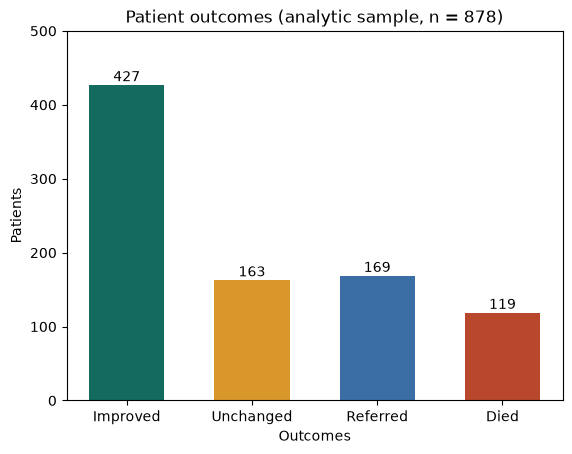

In [9]:
### ----- DATASET OVERVIEW ----- ###

print(df["Patient_Outcome"].value_counts())
counts = df["Patient_Outcome"].value_counts()
counts = counts[["Improved", "Unchanged", "Referred", "Died"]]
colors = ["#126B5E", "#D9962B", "#3B6EA5", "#B8472C"]

plt.bar(counts.index, counts.values, color=colors, width=0.6)
plt.title("Patient outcomes (analytic sample, n = 878)")
plt.xlabel("Outcomes")
plt.ylabel("Patients")
plt.yticks(range(0, 501, 100))
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, v, ha="center")
plt.show()


In [10]:
### --------------- RESULTS (PART A: Section 1): Distribution & Assumptions Checks --------------- ###

for col in ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]:
    print("\n")
    print("_______________", col, "_______________")

    table = pd.crosstab(index=df["Patient_Outcome"], values=df[col], columns="", aggfunc=["skew", "kurt"])
    print(table)
    
    g1 = df.loc[df["Patient_Outcome"] == "Improved", col]
    g2 = df.loc[df["Patient_Outcome"] == "Died", col]
    g3 = df.loc[df["Patient_Outcome"] == "Referred", col]
    g4 = df.loc[df["Patient_Outcome"] == "Unchanged", col]

    test = levene(g1, g2, g3, g4, center="median")
    
    test1 = shapiro(g1)
    test2 = shapiro(g2)
    test3 = shapiro(g3)
    test4 = shapiro(g4)
    print()

    print("Shapiro p_value for Improved:", test1.pvalue)
    print("Shapiro p_value for Died:", test2.pvalue)
    print("Shapiro p_value for Referred:", test3.pvalue)
    print("Shapiro p_value for Unchanged:", test4.pvalue)
    print()

    print("Levene F statistic:", test.statistic)
    print("Levene P_value:", test.pvalue)  



_______________ Temperature_C _______________
                     skew      kurt
col_0                              
Patient_Outcome                    
Died            -0.022437  0.607772
Improved        -0.085339  0.018879
Referred        -0.044434 -0.582765
Unchanged        0.102527  0.195171

Shapiro p_value for Improved: 0.08340495651802027
Shapiro p_value for Died: 0.6429307922861707
Shapiro p_value for Referred: 0.10096311327038393
Shapiro p_value for Unchanged: 0.727220201975749

Levene F statistic: 1.524174154750977
Levene P_value: 0.206720958042894


_______________ Pulse_Rate_bpm _______________
                     skew      kurt
col_0                              
Patient_Outcome                    
Died             0.248956 -0.322487
Improved         0.100865 -0.476009
Referred        -0.077634  0.312889
Unchanged       -0.235667  0.111291

Shapiro p_value for Improved: 0.0008457005712392853
Shapiro p_value for Died: 0.4368200015241448
Shapiro p_value for Referred: 0.3

In [11]:
### ----- RESULTS (PART A: Section 2): Statistical Association with Effect Sizes----- ###

##_______________ Vital Signs _______________##
for col in ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]:

    #_______________ Groups for Analysis _______________#
    print("\n")
    print(*"___"*3,col,"VS.", "Patient Outcome",*"___"*3)
    
    g1 = df.loc[df["Patient_Outcome"] == "Improved", col]
    g2 = df.loc[df["Patient_Outcome"] == "Died", col]
    g3 = df.loc[df["Patient_Outcome"] == "Referred", col]
    g4 = df.loc[df["Patient_Outcome"] == "Unchanged", col]

    groups = [g1, g2, g3, g4]

    #_______________ Descriptive Analysis ___________________#
    table = pd.crosstab(index=df["Patient_Outcome"], values=df[col], columns="", aggfunc=["count", "mean", "std"])
    print(table)
    print()

    for g in groups:
        Q1 = g.quantile(0.25)
        Q2 = g.quantile(0.5)
        Q3 = g.quantile(0.75)
        print("Median (IQR):",Q2,"(",Q1,"-", Q3,")")

    #_______________ Sample Size & Number of groups _______________#
    n = len(df)
    k = len(groups)

    #_______________ Hypothesis Testing_______________#
    from scipy.stats import f_oneway, kruskal
    import pingouin as pg

    print("\n")
    result1 = f_oneway(g1, g2, g3, g4)
    result2 = f_oneway(g1, g2, g3, g4, equal_var=False)
    result3 = kruskal(g1, g2, g3, g4)

    #_______________ Degress of Freedoms_______________#
    # Standard Oneway ANOVA
    dfb_standard = k - 1
    dfw_standard = n - k
    # Welch Oneway ANOVA
    dfw_welch = pg.welch_anova(dv=col, between="Patient_Outcome", data=df).loc[0, "ddof2"]
    dfb_welch = k - 1 
    # Kruskal Wallis
    df_kruskal = k - 1
    

    #_______________ Effect Sizes Analysis _______________#
    # Standard Oneway ANOVA
    eta_sqrd = (result1.statistic * dfb_standard) / ((result1.statistic * dfb_standard) + dfw_standard)
    omega_sqrd = (dfb_standard * (result1.statistic - 1)) / ((dfb_standard *  result1.statistic) + (dfw_standard + 1))
    # Kruskal Wallis
    elipson_sqrd = (result3.statistic - k + 1) / (n - k)


    #_______________ Results _______________#
    print("Results_________:" )
    print("Oneway ANOVA (Standard):","F","(",dfb_standard,",",dfw_standard,")","=",result1.statistic.round(3),",","Pvalue =",result1.pvalue,",","eta_squared =",eta_sqrd.round(3),",", "omega_squared =",omega_sqrd.round(3))
    print("Welch ANOVA:","F","(",dfb_welch,",",dfw_welch.round(3),")","=",result2.statistic.round(3),",","Pvalue =",result2.pvalue)
    print("Kruskal-wallis test:","H","(",df_kruskal,")",",","=",result3.statistic.round(3),",","Pvalue =",result3.pvalue,",", "Elipson_squared =",elipson_sqrd)
    print(*"+++"*5)



_ _ _ _ _ _ _ _ _ Temperature_C VS. Patient Outcome _ _ _ _ _ _ _ _ _
                count       mean       std
col_0                                     
Patient_Outcome                           
Died              119  37.495798  0.529374
Improved          427  36.609368  0.618233
Referred          169  37.443787  0.586434
Unchanged         163  37.081595  0.624227

Median (IQR): 36.6 ( 36.2 - 37.0 )
Median (IQR): 37.5 ( 37.2 - 37.8 )
Median (IQR): 37.4 ( 37.1 - 37.9 )
Median (IQR): 37.1 ( 36.7 - 37.5 )


Results_________:
Oneway ANOVA (Standard): F ( 3 , 874 ) = 118.032 , Pvalue = 3.5511228592201925e-64 , eta_squared = 0.288 , omega_squared = 0.286
Welch ANOVA: F ( 3 , 343.886 ) = 124.233 , Pvalue = 1.606308700846404e-54
Kruskal-wallis test: H ( 3 ) , = 261.243 , Pvalue = 2.4204859308785615e-56 , Elipson_squared = 0.2954726253938592
+ + + + + + + + + + + + + + +


_ _ _ _ _ _ _ _ _ Pulse_Rate_bpm VS. Patient Outcome _ _ _ _ _ _ _ _ _
                count        mean        std
c

In [12]:
### --------------- Correlation & Multicollinearity --------------- ###

from scipy.stats import pearsonr

test1 = pearsonr(df["Temperature_C"], df["Pulse_Rate_bpm"]) 
test2 = pearsonr(df["Temperature_C"], df["Respiratory_Rate_cpm"])
test3 = pearsonr(df["Temperature_C"], df["Systolic_BP_mmHg"])
test4 = pearsonr(df["Temperature_C"], df["Diastolic_BP_mmHg"])
test5 = pearsonr(df["Pulse_Rate_bpm"], df["Respiratory_Rate_cpm"])
test6 = pearsonr(df["Pulse_Rate_bpm"], df["Systolic_BP_mmHg"])
test7 = pearsonr(df["Pulse_Rate_bpm"], df["Diastolic_BP_mmHg"])
test8 = pearsonr(df["Respiratory_Rate_cpm"], df["Systolic_BP_mmHg"])
test9 = pearsonr(df["Respiratory_Rate_cpm"], df["Diastolic_BP_mmHg"])
test10 = pearsonr(df["Systolic_BP_mmHg"], df["Diastolic_BP_mmHg"])

tests = {
    "Temperature vs Pulse rate":        test1,
    "Temperature vs Respiratory rate":  test2,
    "Temperature vs Systolic BP":       test3,
    "Temperature vs Diastolic BP":      test4,
    "Pulse rate vs Respiratory rate":   test5,
    "Pulse rate vs Systolic BP":        test6,
    "Pulse rate vs Diastolic BP":       test7,
    "Respiratory rate vs Systolic BP":  test8,
    "Respiratory rate vs Diastolic BP": test9,
    "Systolic BP vs Diastolic BP":      test10,
}

result = pd.DataFrame({"Pair": list(tests),
              "Pearson r": [t.statistic for t in tests.values()],
              "p-value":   [t.pvalue for t in tests.values()]})
print("Correlation Coefficients with Pvalues...............")
print(result)


from sklearn.linear_model import LinearRegression

V = ["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm",
     "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]

vif = {}
for col in V:
    others = [c for c in V if c != col]
    r2 = LinearRegression().fit(df[others], df[col]).score(df[others], df[col])
    vif[col] = 1 / (1 - r2)          # VIF = 1 / (1 - R²)
    
print()
print("Variance Inflation Factors (VIF):...............")
print(pd.Series(vif).round(1))

Correlation Coefficients with Pvalues...............
                               Pair  Pearson r        p-value
0         Temperature vs Pulse rate   0.737736  1.209922e-151
1   Temperature vs Respiratory rate   0.713867  1.084392e-137
2        Temperature vs Systolic BP  -0.526774   7.605860e-64
3       Temperature vs Diastolic BP  -0.608334   5.438438e-90
4    Pulse rate vs Respiratory rate   0.775512  3.688526e-177
5         Pulse rate vs Systolic BP  -0.534807   4.131912e-66
6        Pulse rate vs Diastolic BP  -0.619586   3.228316e-94
7   Respiratory rate vs Systolic BP  -0.537440   7.248693e-67
8  Respiratory rate vs Diastolic BP  -0.617776   1.585883e-93
9       Systolic BP vs Diastolic BP   0.482825   1.801910e-52

Variance Inflation Factors (VIF):...............
Temperature_C           2.6
Pulse_Rate_bpm          3.2
Respiratory_Rate_cpm    3.0
Systolic_BP_mmHg        1.6
Diastolic_BP_mmHg       1.9
dtype: float64


In [13]:
### ---------- PART B ---------- ###
## _______________ Importing Libraries _______________ ##
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


## _______________ Patient's Outcomes Arrangement _______________ ##
ORDER = ["Improved", "Unchanged", "Referred", "Died"]

## _______________ Features X's & Target y _______________ ##
X = df[["Temperature_C", "Pulse_Rate_bpm", "Respiratory_Rate_cpm", "Systolic_BP_mmHg", "Diastolic_BP_mmHg"]]
y = df["Patient_Outcome"].map({o: i for i, o in enumerate(ORDER)})

## _______________ Splitting Data ____________________ ##
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=20261114)

## ________________ Standardizing X's Values _______________ ##
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

##_______________ Sample Design _______________##
print("Training Sets...............")
# Training sets...............
print(y_train.value_counts())
print()
print("Testing Sets...............")
# Testing sets...............
print(y_test.value_counts())
print()


##_______________ Plain Logistic Regression _______________##
#-----------------------------------------------------------#
print(*"___"*5, "PLAIN LOGISTIC REGRESSION", *"___"*5)

plain_model = LogisticRegression()
plain_model.fit(X_train_s, y_train)

y_actual = y_test.values
y_predicted = plain_model.predict(X_test_s)
y_prob = plain_model.predict_proba(X_test_s)

print("Confusion Matrix...............")
cm = confusion_matrix(y_actual, y_predicted, labels=[0, 1, 2, 3])
print(cm)
print()

print("Coefficients...............")
print(plain_model.coef_)
print()

print("Model Evaluation...............")
print("Accuracy_Score: ", accuracy_score(y_actual, y_predicted))
print("Patient Outcome:",ORDER)
print("precision_Score:", precision_score(y_actual, y_predicted, average=None))
print("Recall_Score:   ", recall_score(y_actual, y_predicted, average=None))
print("F1_Score:       ", f1_score(y_actual, y_predicted, average=None))
print("AUC_Score:      ", roc_auc_score(y_actual, y_prob, multi_class="ovr", average=None))
print()


##_______________ Balanced Logistic Regression _______________##
#--------------------------------------------------------------#
print(*"___"*5, "BALANCED LOGISTIC REGRESSION", *"___"*5)
balanced_model = LogisticRegression(max_iter=2000, class_weight="balanced")
balanced_model.fit(X_train_s, y_train)

y_actual = y_test.values
y_predicted = balanced_model.predict(X_test_s)
y_prob = balanced_model.predict_proba(X_test_s)

print("Confusion Matrix...............")
cm = confusion_matrix(y_actual, y_predicted, labels=[0, 1, 2, 3])
print(cm)
print()

print("Coefficients...............")
print(balanced_model.coef_)
print()

print("Model Evaluation...............")
print("Accuracy_Score: ", accuracy_score(y_actual, y_predicted))
print("Patient Outcome:",ORDER)
print("precision_Score:", precision_score(y_actual, y_predicted, average=None))
print("Recall_Score:   ", recall_score(y_actual, y_predicted, average=None))
print("F1_Score:       ", f1_score(y_actual, y_predicted, average=None))
print("AUC_Score:      ", roc_auc_score(y_actual, y_prob, multi_class="ovr", average=None))

Training Sets...............
Patient_Outcome
0    342
2    135
1    130
3     95
Name: count, dtype: int64

Testing Sets...............
Patient_Outcome
0    85
2    34
1    33
3    24
Name: count, dtype: int64

_ _ _ _ _ _ _ _ _ _ _ _ _ _ _ PLAIN LOGISTIC REGRESSION _ _ _ _ _ _ _ _ _ _ _ _ _ _ _
Confusion Matrix...............
[[72  2 10  1]
 [27  1  5  0]
 [14  3 11  6]
 [ 3  0 12  9]]

Coefficients...............
[[-0.32931898 -0.44942942 -0.69777243  0.21986758  0.1518148 ]
 [ 0.09824212  0.01270301 -0.38550306 -0.06700712  0.09702906]
 [ 0.24215573  0.21285059  0.36799794 -0.02504766 -0.11810786]
 [-0.01107886  0.22387582  0.71527755 -0.12781279 -0.13073601]]

Model Evaluation...............
Accuracy_Score:  0.5284090909090909
Patient Outcome: ['Improved', 'Unchanged', 'Referred', 'Died']
precision_Score: [0.62068966 0.16666667 0.28947368 0.5625    ]
Recall_Score:    [0.84705882 0.03030303 0.32352941 0.375     ]
F1_Score:        [0.71641791 0.05128205 0.30555556 0.45      ]
AUC_Sco

In [14]:
## --------------- PART C --------------- ##




In [76]:
df.to_excel(r"C:\0 GIT HUB\DATASETS\Cleaned_Synthetic_Healthcare_Vitals_Outcomes_878.xlsx", index=False) 
print()

print("File Saved Successifully..........")
print()

print(df.info())

File Saved Successifully..........
<class 'pandas.DataFrame'>
Index: 878 entries, 0 to 987
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Patient_ID                   878 non-null    str    
 1   Temperature_C                878 non-null    float64
 2   Pulse_Rate_bpm               878 non-null    float64
 3   Respiratory_Rate_cpm         878 non-null    float64
 4   Systolic_BP_mmHg             878 non-null    float64
 5   Diastolic_BP_mmHg            878 non-null    float64
 6   Patient_Outcome              878 non-null    str    
 7   Pulse_Pressure_mmHg          878 non-null    float64
 8   Mean_Arterial_Pressure_mmHg  878 non-null    float64
 9   Shock_Index                  878 non-null    float64
dtypes: float64(8), str(2)
memory usage: 87.4 KB
